In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import logging
import os
import warnings
from typing import List, Tuple
import torch
from sklearn.metrics import silhouette_score
#import gseapy as gp

import anndata as ad
import pandas as pd
import scanpy as sc
import scib_metrics
from datasets import load_from_disk
from matplotlib.colors import Normalize
#import squidpy as sq
from tqdm import tqdm
from app.inference import (
    tokenize_adata,
    harmonize_adata)
from app.inference import (embed_dataset,
                       harmonize_adata,
                       perturb_dataset,
                       harmonize_tokenize_embed_pipeline,
                       get_gene_embed,
                       get_average_gene_embed,
                       get_spatial_score,
                       get_emd_distance)
from nichejepa.utils.evaluation import (get_top_gene_score,
                                        get_top_gene_pairs)
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [ ]:
folder_path = '/nfs/team361/dj17/TERRA_DJ/Integration_disease/adatas'
label_key = 'n_genes_by_counts'
spot_size = 20

In [ ]:
if folder_path:
    for filename in os.listdir(folder_path):
        if filename.endswith(".h5ad"):
            file_path = os.path.join(folder_path, filename)
            print(f"Reading {file_path}.")
    
            # Load AnnData
            adata = sc.read_h5ad(file_path)
            print(adata)
        
            if 'fov' not in adata.obs.columns.tolist() and 'FOV' not in adata.obs.columns.tolist():
                print(file_path)
                adata.write(file_path.replace('/adatas/', '/adatas_processed/'))
            
            # (Optional): plot each tissue with labels 
            sc.pl.spatial(adata,
                          spot_size=spot_size,
                          color=label_key)

In [ ]:
adata.obs

In [ ]:
adata.obs

In [ ]:
adata.obs.columns

Do not use:
- /nfs/team361/dj17/TERRA_DJ/Integration_disease/adatas/SLE8.3_with_emb_GENECLEAN_commongenes_qc.h5ad

In [ ]:
adata_test = sc.read_h5ad('/nfs/team361/dj17/TERRA_DJ/Integration_disease/adatas/SLE8.3_with_emb_GENECLEAN_commongenes_qc.h5ad')

In [ ]:
adata_test.obs.columns

In [ ]:
# Split AnnData objects with multiple fovs per fov
if folder_path:
    for filename in os.listdir(folder_path):
        if filename.endswith(".h5ad"):
            file_path = os.path.join(folder_path, filename)
            print(f"Reading {file_path}.")
    
            # Load AnnData
            adata = sc.read_h5ad(file_path)
        
            if 'fov' in adata.obs.columns.tolist() or 'FOV' in adata.obs.columns.tolist():

                if 'CenterX_global_px' in adata.obs.columns.tolist():
                    adata.obsm['spatial'] = np.column_stack((
                        adata.obs['CenterX_global_px'].values,
                        adata.obs['CenterY_global_px'].values))
                elif 'x' in adata.obs.columns.tolist():
                    adata.obsm['spatial'] = np.column_stack((
                        adata.obs['x'].values,
                        adata.obs['y'].values))
                elif 'x_slide_mm' in adata.obs.columns.tolist():
                    adata.obsm['spatial'] = np.column_stack((
                        adata.obs['x_slide_mm'].values,
                        adata.obs['y_slide_mm'].values))                    
                    
            
                adata.write(file_path.replace('/adatas/', '/adatas_processed/'))
                # (Optional): plot each tissue with labels 
                sc.pl.spatial(adata,
                              spot_size=spot_size,
                              color=label_key)

In [ ]:
adata_test = sc.read_h5ad('/nfs/team361/dj17/TERRA_DJ/Integration_disease/adatas/SLE4_with_emb_GENECLEAN_commongenes_qc.h5ad')

In [ ]:
adata_test.obs.columns

In [ ]:
folder_path = '/nfs/team361/dj17/TERRA_DJ/Integration_disease/adatas_processed'
spot_size = 20

In [ ]:
if folder_path:
    for filename in os.listdir(folder_path):
        if filename.endswith(".h5ad"):
            file_path = os.path.join(folder_path, filename)
            print(f"Reading {file_path}.")
    
            # Load AnnData
            adata = sc.read_h5ad(file_path)
            print(adata)
        
            if 'fov' not in adata.obs.columns.tolist() and 'FOV' not in adata.obs.columns.tolist():
                print(file_path)
                adata.write(file_path.replace('/adatas/', '/adatas_processed/'))
            
            # (Optional): plot each tissue with labels 
            sc.pl.spatial(adata,
                          spot_size=spot_size,
                          color=label_key)

In [ ]:
folder_path = '/nfs/team361/dj17/TERRA_DJ/Integration_healthy/adatas'
label_key = 'n_genes_by_counts'
spot_size = 20

In [ ]:
if folder_path:
    for filename in os.listdir(folder_path):
        if filename.endswith(".h5ad"):
            file_path = os.path.join(folder_path, filename)
            print(f"Reading {file_path}.")
    
            # Load AnnData
            adata = sc.read_h5ad(file_path)
            print(adata)
        
            if 'fov' not in adata.obs.columns.tolist() and 'FOV' not in adata.obs.columns.tolist():
                print(file_path)
                adata.write(file_path.replace('/adatas/', '/adatas_processed/'))
            
            # (Optional): plot each tissue with labels 
            if 'spatial' in adata.uns.keys():
                del(adata.uns['spatial'])
            sc.pl.spatial(adata,
                          spot_size=spot_size,
                          color=label_key)

In [ ]:
import os
import anndata as ad

folder = "/nfs/team361/sb75/nichejepa-reproducibility/artifacts/embedded_data/11012026_190057_836/kidney_healthy_integration"

# Get all .h5ad files
files = [f for f in os.listdir(folder) if f.endswith(".h5ad")]

# Read them
adatas = []
for f in files:
    path = os.path.join(folder, f)
    print(f"Reading {path}")
    adata = ad.read_h5ad(path)
    adatas.append(adata)

# Concatenate
adata_merged = ad.concat(adatas, join="outer", label="batch", keys=files)

# Save
output_path = os.path.join(folder, "concatenated.h5ad")
adata_merged.write(output_path)

print(f"Saved merged AnnData to {output_path}")

In [ ]:
folder = "/nfs/team361/sb75/nichejepa-reproducibility/artifacts/embedded_data/11012026_190057_836/kidney_healthy_integration"
output_path = os.path.join(folder, "concatenated.h5ad")
adata_merged = sc.read_h5ad(output_path)
adata_merged

In [ ]:
adata_merged.obs['Study_slice_id'].unique()

In [ ]:
import numpy as np

n_target = 100_000
rng = np.random.default_rng(42)

# Get group sizes
group_counts = adata_merged.obs["Study_slice_id"].value_counts()

# Compute proportional allocation
proportions = group_counts / group_counts.sum()
n_per_group = (proportions * n_target).round().astype(int)

# Fix rounding errors so total is exactly 100k
diff = n_target - n_per_group.sum()
if diff != 0:
    # Adjust the largest groups slightly
    largest_groups = n_per_group.sort_values(ascending=False).index[:abs(diff)]
    for g in largest_groups:
        n_per_group[g] += np.sign(diff)

# Collect sampled indices
sampled_indices = []

for group, n in n_per_group.items():
    group_idx = np.where(adata_merged.obs["Study_slice_id"] == group)[0]
    sampled = rng.choice(group_idx, size=n, replace=False)
    sampled_indices.append(sampled)

sampled_indices = np.concatenate(sampled_indices)

# Subset
adata_sample = adata_merged[sampled_indices].copy()

print(adata_sample)

In [ ]:
adata_sample.obs['Study_slice_id'].value_counts()

In [ ]:
import rapids_singlecell as rsc

In [ ]:
adata_merged

In [ ]:
rsc.pp.neighbors(adata_merged,
                 n_neighbors=15,
                 use_rep=f'neighborhood_emb',
                 n_pcs=20,
                 key_added=f'neighborhood')

In [ ]:
rsc.tl.umap(adata_merged,
            neighbors_key=f'neighborhood',
            key_added=f'neighborhood_umap')

In [ ]:
adata_merged.obsm['umap'] = adata_merged.obsm['neighborhood_umap']

In [ ]:
adata_merged.obs.columns

In [ ]:
sc.pl.umap(adata_merged,
           color='Platform',
           show=False)

In [ ]:
output_path

In [ ]:
output_path = os.path.join(folder, "concatenated_processed.h5ad")
adata_merged.write(f"{output_path}")
adata_merged

In [ ]:
import os
import anndata as ad

folder = "/nfs/team361/sb75/nichejepa-reproducibility/artifacts/embedded_data/11012026_190057_836/kidney_disease_integration"

# Get all .h5ad files
files = [f for f in os.listdir(folder) if f.endswith(".h5ad")]

# Read them
adatas = []
for f in files:
    path = os.path.join(folder, f)
    print(f"Reading {path}")
    adata = ad.read_h5ad(path)
    adatas.append(adata)

# Concatenate
adata_merged = ad.concat(adatas, join="outer", label="batch", keys=files)

# Save
#import pandas as pd

#col = "Annotation.Lvl2"
#adata_merged.obs[col] = adata_merged.obs[col].astype("object")   # pandas StringDtype
#col = "Niche"
#adata_merged.obs[col] = adata_merged.obs[col].astype("object")   # pandas StringDtype
#adata_merged.obs['x_centroid'] = adata_merged.obs['x_centroid'].astype(float)
adata_merged.obs.drop("_index", axis=1, inplace=True)
output_path = os.path.join(folder, "concatenated.h5ad")
adata_merged.write(output_path)

print(f"Saved merged AnnData to {output_path}")

In [ ]:
adata_merged.obs.drop("_index", axis=1, inplace=True)
output_path = os.path.join(folder, "concatenated.h5ad")
adata_merged.write(output_path)

print(f"Saved merged AnnData to {output_path}")

In [ ]:
folder = "/nfs/team361/sb75/nichejepa-reproducibility/artifacts/embedded_data/11012026_190057_836/kidney_disease_integration"
output_path = os.path.join(folder, "concatenated.h5ad")
adata_merged = sc.read_h5ad(output_path)
adata_merged

In [ ]:
# Save
import pandas as pd

col = "Annotation.Lvl2"
adata_merged.obs[col] = adata_merged.obs[col].astype("object")   # pandas StringDtype
col = "Niche"
adata_merged.obs[col] = adata_merged.obs[col].astype("object")   # pandas StringDtype
adata_merged.obs['x_centroid'] = adata_merged.obs['x_centroid'].astype(float)
adata_merged.obs['y_centroid'] = adata_merged.obs['y_centroid'].astype(float)
adata_merged.obs["transcript_counts"] = pd.to_numeric(
    adata_merged.obs["transcript_counts"], errors="coerce"
).astype("Int64")
for col in adata_merged.obs.columns:
    if pd.api.types.is_string_dtype(adata_merged.obs[col].dtype) and str(adata_merged.obs[col].dtype) == "string":
        adata_merged.obs[col] = adata_merged.obs[col].astype(object)
output_path = os.path.join(folder, "concatenated.h5ad")
adata_merged.write(output_path)

print(f"Saved merged AnnData to {output_path}")

In [ ]:
adata_merged.obs.drop("_index", axis=1, inplace=True)

In [ ]:
# Save
import pandas as pd

for col in adata_merged.obs.columns.tolist():
    adata_merged.obs[col] = adata_merged.obs[col].astype("string")   # pandas StringDtype
#adata_merged.obs.drop("_index", axis=1, inplace=True)
output_path = os.path.join(folder, "concatenated.h5ad")
adata_merged.write(output_path)

print(f"Saved merged AnnData to {output_path}")

In [ ]:
adata_merged.obsm

In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"   # make exactly 1 GPU visible

import cupy as cp
cp.cuda.Device(0).use()

import rapids_singlecell as rsc

In [ ]:
import cupy as cp
print("CuPy device count:", cp.cuda.runtime.getDeviceCount())
print("Current device:", cp.cuda.runtime.getDevice())

In [41]:
rsc.pp.neighbors(adata_merged,
                 n_neighbors=15,
                 use_rep=f'neighborhood_emb',
                 n_pcs=20,
                 key_added=f'neighborhood')

NameError: name 'adata_merged' is not defined

In [ ]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.device_count())

In [ ]:
rsc.tl.umap(adata_merged,
            neighbors_key=f'neighborhood',
            key_added=f'neighborhood_umap')

In [ ]:
sc.pl.umap(adata_merged,
           color='Platform',
           show=False)

In [1]:
import scanpy as sc
import rapids_singlecell as rsc

/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata_sample = sc.read_h5ad('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/embedded_data/11012026_190057_836/kidney_disease_integration/CosMx_Biopsy2_commongenes_qc.h5ad')

In [5]:
adata_sample.obsm['neighborhood_emb']

array([[ 0.65332913, -0.88116777,  0.13119958, ..., -0.23417939,
         0.22412401, -0.5253092 ],
       [ 0.6621433 , -0.82485396,  0.16402963, ..., -0.29445237,
         0.19974007, -0.5996761 ],
       [ 0.65013546, -0.66938126,  0.12153837, ..., -0.28660768,
         0.26104337, -0.53112096],
       ...,
       [ 0.5326837 , -0.80319405,  0.01008417, ..., -0.28879836,
         0.20381773, -0.60502976],
       [ 0.58113426, -0.73888344,  0.02114461, ..., -0.29740408,
         0.21191409, -0.5613578 ],
       [ 0.6294623 , -0.6919093 ,  0.06653278, ..., -0.3030303 ,
         0.23669127, -0.5270339 ]], shape=(16015, 384), dtype=float32)

In [42]:
rsc.pp.neighbors(adata_sample,
                 n_neighbors=15,
                 use_rep=f'cell_emb',
                 n_pcs=20,
                 key_added=f'neighborhood')

In [43]:
rsc.tl.umap(adata_sample,
            neighbors_key=f'neighborhood',
            key_added=f'neighborhood_umap')

In [44]:
adata_sample.obsm['umap'] = adata_sample.obsm['neighborhood_umap']

In [45]:
adata_sample.obs

,cell_id,x_centroid,y_centroid,transcript_counts,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,...,nucleus_area,nucleus_count,segmentation_method,Study_slice_id,Platform,n_genes_by_counts,log1p_n_genes_by_counts,log1p_total_counts,pct_counts_in_top_20_genes,n_genes
1,aaachdbk-1,433.566742,1223.074341,74,0,0,0,0,0,74.0,...,48.362346,2,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,CV1-KID-0-FT-5-S5,Xenium 5k,65,4.189655,4.317488,39.189189,8
4,aaadnfcd-1,588.940063,1476.059937,12,0,0,0,0,0,12.0,...,NaN,0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,CV1-KID-0-FT-5-S5,Xenium 5k,12,2.564949,2.564949,100.000000,1
5,aaafahdi-1,598.961426,1429.068726,36,0,0,0,0,0,36.0,...,57.664533,1,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,CV1-KID-0-FT-5-S5,Xenium 5k,31,3.465736,3.610918,69.444444,2
6,aaafofeo-1,520.871155,933.671814,78,0,0,0,0,0,78.0,...,42.627502,1,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,CV1-KID-0-FT-5-S5,Xenium 5k,69,4.248495,4.369448,37.179487,6
7,aaahigan-1,576.218994,903.879700,45,0,0,0,0,0,45.0,...,34.725158,1,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,CV1-KID-0-FT-5-S5,Xenium 5k,43,3.784190,3.828641,48.888889,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84137,oiplalia-1,2325.719482,3461.117676,18,0,0,0,0,0,18.0,...,17.881876,1,Segmented by nucleus expansion of 5.0µm,CV1-KID-0-FT-5-S5,Xenium 5k,17,2.890372,2.944439,100.000000,2
84138,oipljnpf-1,2198.454834,3527.210449,19,0,0,0,0,0,19.0,...,15.443438,1,Segmented by nucleus expansion of 5.0µm,CV1-KID-0-FT-5-S5,Xenium 5k,18,2.944439,2.995732,100.000000,0
84140,oipmikic-1,1647.244629,4900.171875,45,1,0,0,0,0,45.0,...,35.989533,1,Segmented by nucleus expansion of 5.0µm,CV1-KID-0-FT-5-S5,Xenium 5k,35,3.583519,3.828641,66.666667,3
84141,oippbmcc-1,1970.706787,5569.414062,14,0,0,0,0,0,14.0,...,15.488594,1,Segmented by nucleus expansion of 5.0µm,CV1-KID-0-FT-5-S5,Xenium 5k,14,2.708050,2.708050,100.000000,0


In [46]:
adata_raw.X.toarray().sum(1)

array([9., 1., 4., ..., 3., 0., 4.], shape=(73352,), dtype=float32)

In [30]:
adata_sample = sc.read_h5ad('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/embedded_data/11012026_190057_836/kidney_disease_integration/CV1-KID-0-FT-5-S5_with_emb_NEMO_cosmxCOMMON_qc.h5ad')

In [50]:
adata_sample.X.toarray().sum(0)

array([3.73724121e+02, 1.82415482e+02, 1.69261975e+03, 5.31775208e+02,
       1.46498901e+03, 1.73979950e+02, 1.89464767e+02, 6.30596191e+02,
       2.48264496e+02, 7.66516495e+01, 5.82728333e+02, 1.73286781e+01,
       1.39558167e+02, 1.10328186e+02, 4.36682739e+01, 6.23832464e+00,
       1.44174622e+02, 3.22262451e+02, 1.77851135e+02, 1.04495323e+02,
       3.18847694e+01, 1.49572644e+03, 9.26879590e+03, 1.64969025e+02,
       9.21808655e+02, 1.24766493e+01, 1.67179810e+02, 3.60436554e+01,
       5.05997467e+01, 4.50729126e+02, 2.62415100e+02, 2.04308533e+02,
       4.71994659e+02, 1.57462189e+02, 1.88078430e+02, 1.54504077e+03,
       4.96528931e+02, 2.91121807e+01, 2.46656170e+01, 9.95255127e+01,
       3.28042053e+02, 1.51629333e+02, 2.13607117e+02, 5.02087677e+02,
       6.30763931e+01, 5.09348389e+03, 7.36489197e+02, 7.62461929e+01,
       2.63631500e+02, 7.31951965e+02, 2.07774246e+02, 8.31776619e+00,
       4.82326202e+01, 1.31697969e+01, 5.34901123e+01, 8.31776619e+00,
      

In [39]:
adata_sample.obs.columns

Index(['cell_id', 'x_centroid', 'y_centroid', 'transcript_counts',
       'control_probe_counts', 'genomic_control_counts',
       'control_codeword_counts', 'unassigned_codeword_counts',
       'deprecated_codeword_counts', 'total_counts', 'cell_area',
       'nucleus_area', 'nucleus_count', 'segmentation_method',
       'Study_slice_id', 'Platform', 'n_genes_by_counts',
       'log1p_n_genes_by_counts', 'log1p_total_counts',
       'pct_counts_in_top_20_genes', 'n_genes'],
      dtype='object')

In [48]:
adata_sample.obsm['cell_emb']

array([[ 0.5416796 , -0.14606917, -0.37969586, ..., -0.3936926 ,
         0.42797548, -0.33972842],
       [ 0.5182099 , -0.17292295, -1.1722623 , ..., -0.5172572 ,
         0.32918972, -0.7645795 ],
       [ 0.516047  , -0.13103202, -0.70827687, ..., -0.5934937 ,
         0.24916855, -0.68866235],
       ...,
       [ 0.41903177, -0.04285423, -1.0206488 , ..., -0.6460553 ,
         0.51007056, -0.7196891 ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.74383956, -0.05881932, -0.6435044 , ..., -0.37258363,
         0.19002354, -0.40399426]], shape=(73352, 384), dtype=float32)

<Axes: title={'center': 'total_counts'}, xlabel='UMAP1', ylabel='UMAP2'>

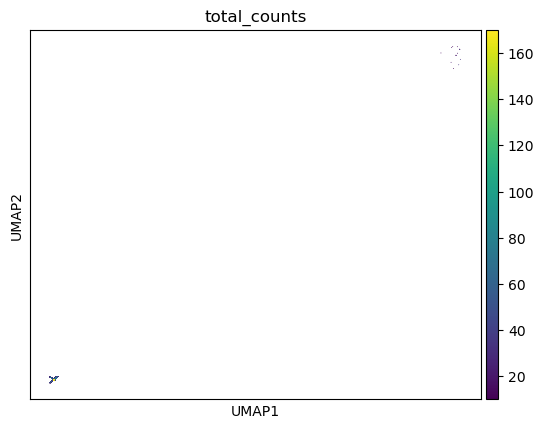

In [47]:
sc.pl.umap(adata_sample,
           color='total_counts',
           show=False)

In [59]:
adata_embed_1 = sc.read_h5ad('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/embedded_data/11012026_190057_836/kidney_healthy_integration/CV1-KID-0-FT-5-S5_with_emb_NEMO_xeniumCOMMON_qc.h5ad')

In [60]:
rsc.pp.neighbors(adata_embed_1,
                 n_neighbors=15,
                 use_rep=f'neighborhood_emb',
                 #n_pcs=20,
                 key_added=f'neighborhood')

In [61]:
rsc.tl.umap(adata_embed_1,
            neighbors_key=f'neighborhood',
            key_added=f'neighborhood_umap')

In [62]:
adata_embed_1.obsm['umap'] = adata_embed_1.obsm['neighborhood_umap']

<Axes: title={'center': 'total_counts'}, xlabel='UMAP1', ylabel='UMAP2'>

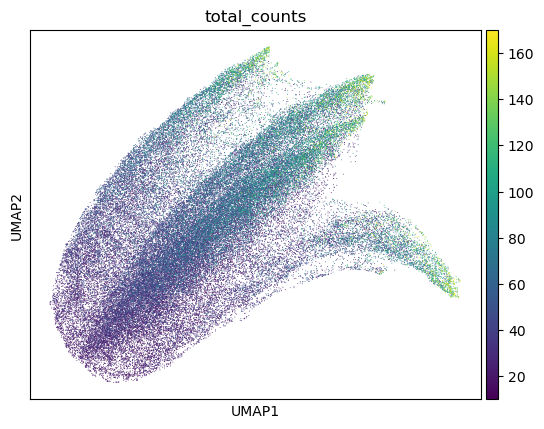

In [63]:
sc.pl.umap(adata_embed_1,
           color='total_counts',
           show=False)

In [64]:
adata_embed_2 = sc.read_h5ad('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/embedded_data/11012026_190057_836/kidney_disease_integration/CV1-KID-0-FT-5-S5_with_emb_NEMO_cosmxCOMMON_qc.h5ad')

In [69]:
rsc.pp.neighbors(adata_embed_2,
                 n_neighbors=15,
                 use_rep=f'cell_emb',
                 #n_pcs=20,
                 key_added=f'cell')

In [70]:
rsc.tl.umap(adata_embed_2,
            neighbors_key=f'cell',
            key_added=f'cell_umap')

In [72]:
adata_embed_2.obsm['umap'] = adata_embed_2.obsm['cell_umap']

<Axes: title={'center': 'total_counts'}, xlabel='UMAP1', ylabel='UMAP2'>

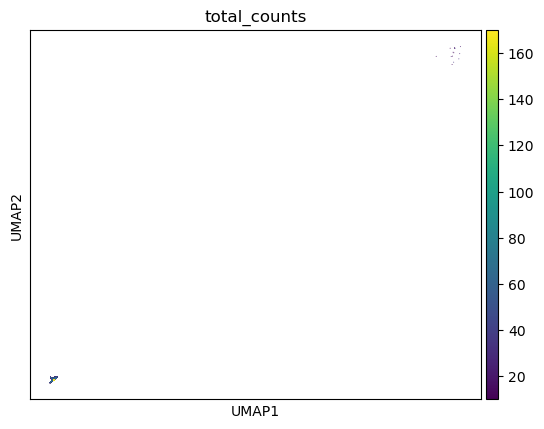

In [73]:
sc.pl.umap(adata_embed_2,
           color='total_counts',
           show=False)

In [8]:
folder_path = '/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads'
label_key = 'Niche'
spot_size = 20

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy9.h5ad.


... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical
... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical


AnnData object with n_obs × n_vars = 17282 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy9.h5ad


/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


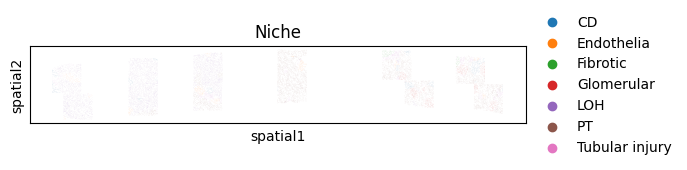

... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical
... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical


Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Nephr3.h5ad.
AnnData object with n_obs × n_vars = 17472 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Nephr3.h5ad


/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


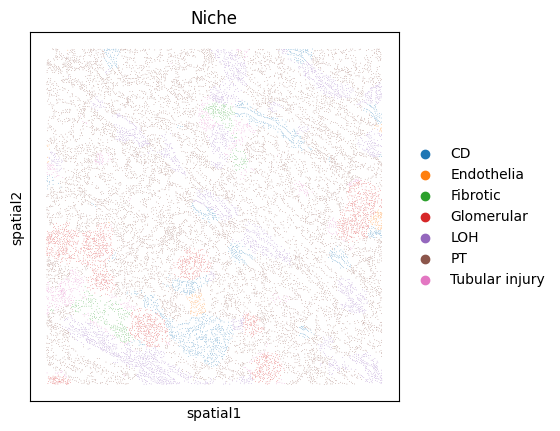

... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical
... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical


Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy2.h5ad.
AnnData object with n_obs × n_vars = 16702 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy2.h5ad


/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


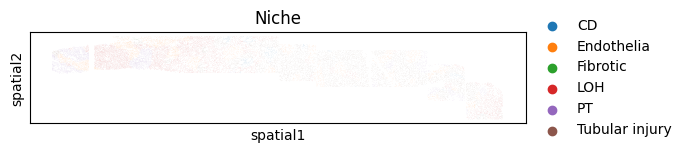

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy7.h5ad.


... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical
... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical


AnnData object with n_obs × n_vars = 20589 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy7.h5ad


/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


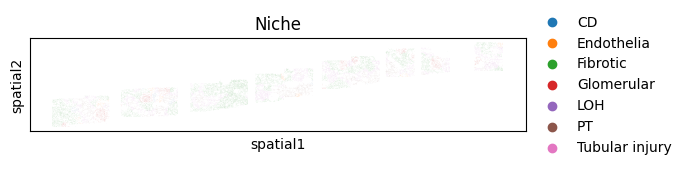

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy6.h5ad.


... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical
... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical


AnnData object with n_obs × n_vars = 25243 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy6.h5ad


/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


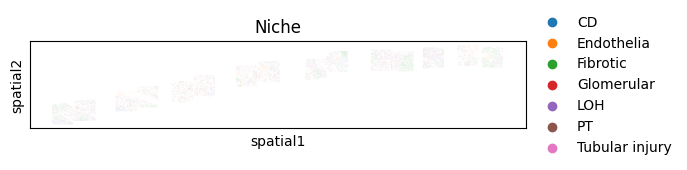

... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical
... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical


Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy3.h5ad.
AnnData object with n_obs × n_vars = 10862 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy3.h5ad


/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


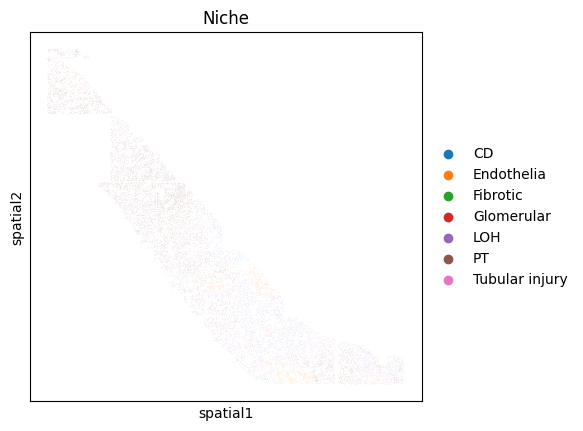

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy1.h5ad.


... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical
... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical


AnnData object with n_obs × n_vars = 25909 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy1.h5ad


/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


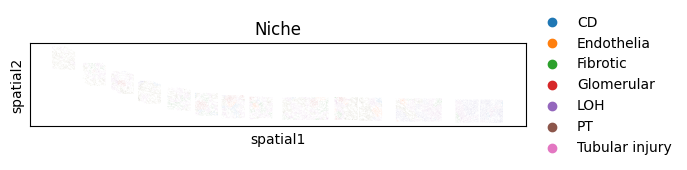

... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical


Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Nephr4.h5ad.
AnnData object with n_obs × n_vars = 17388 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Nephr4.h5ad


... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical
/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


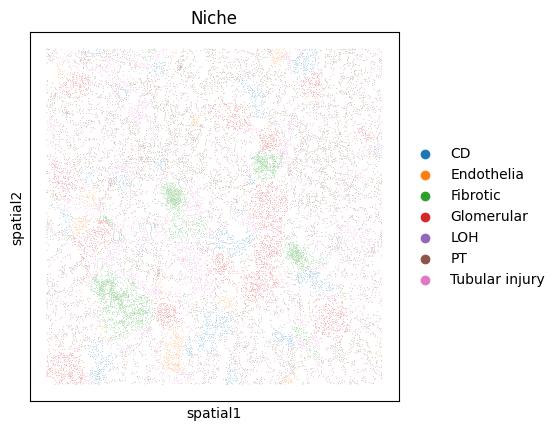

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy8.h5ad.


... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical
... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical


AnnData object with n_obs × n_vars = 21712 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy8.h5ad


/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


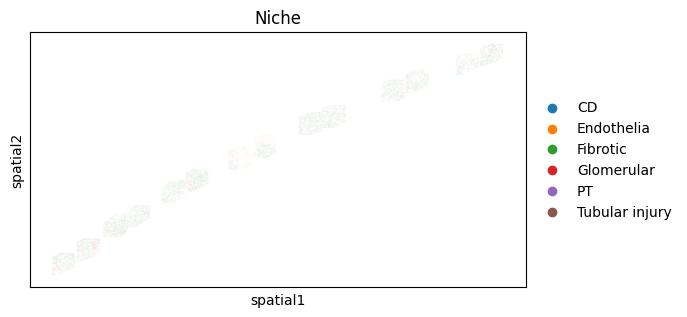

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy5.h5ad.


... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical
... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical


AnnData object with n_obs × n_vars = 27324 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy5.h5ad


/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


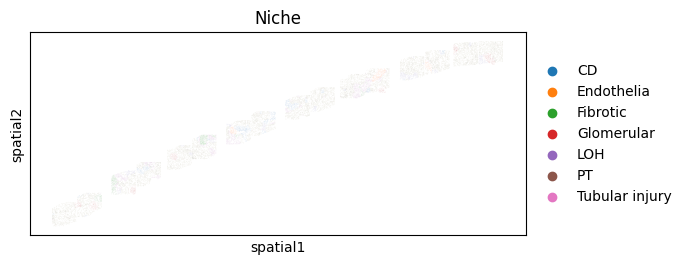

... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical
... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical


Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Nephr1.h5ad.
AnnData object with n_obs × n_vars = 15831 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Nephr1.h5ad


/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


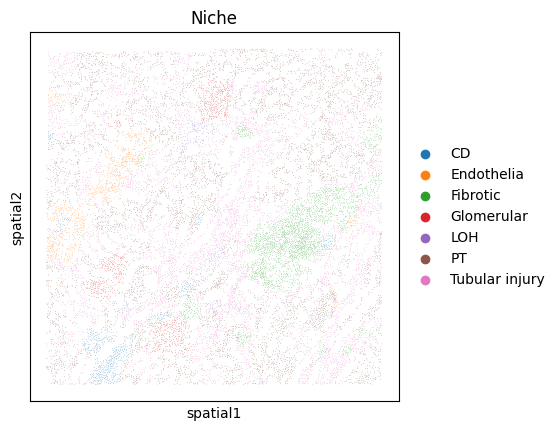

... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical
... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical


Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy4.h5ad.
AnnData object with n_obs × n_vars = 14700 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Biopsy4.h5ad


/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


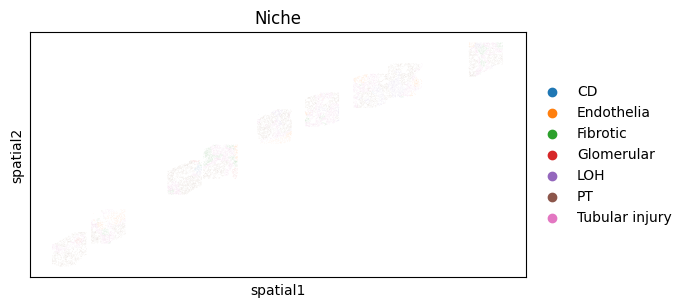

... storing 'Slide_ID' as categorical
... storing 'Specimen_ID' as categorical
... storing 'Sensor_ID' as categorical
... storing 'eGFR' as categorical
... storing 'Fibrosis_percentage' as categorical
... storing 'Niche' as categorical
... storing 'DiseaseDx' as categorical


Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Nephr2.h5ad.
AnnData object with n_obs × n_vars = 15041 × 978
    obs: 'CellName', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'Slide_ID', 'Specimen_ID', 'Sensor_ID', 'FOV', 'eGFR', 'Fibrosis_percentage', 'nCount_Nanostring', 'nFeature_Nanostring', 'Annotation.Lvl1', 'Annotation.Lvl2', 'Niche', 'InjuryState', 'DiseaseDx'
    var: 'features'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/EdinburghCosMx_1k_h5ads/CosMx_Nephr2.h5ad


/tmp/ipykernel_3346085/2471436846.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


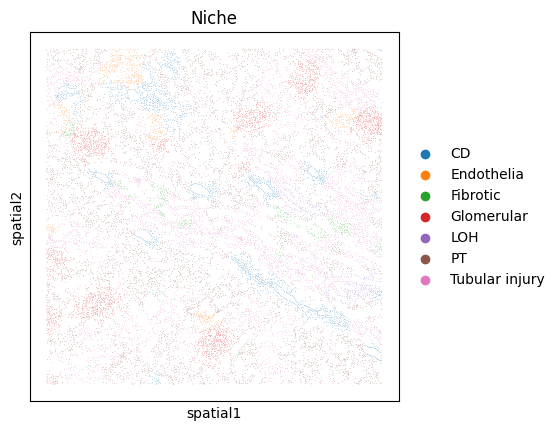

In [34]:
if folder_path:
    for filename in os.listdir(folder_path):
        if filename.endswith(".h5ad"):
            file_path = os.path.join(folder_path, filename)
            print(f"Reading {file_path}.")
    
            # Load AnnData
            adata = sc.read_h5ad(file_path)
            adata.obsm['spatial'] = np.column_stack((
                adata.obs['CenterX_global_px'].values,
                adata.obs['CenterY_global_px'].values))
            del(adata.raw)
            print(adata)
            print(file_path)
            os.makedirs(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/preprocessed_data/{file_path.split("/")[-2]}', exist_ok=True)
                adata.write(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/preprocessed_data/{file_path.split("zeroshot/")[-1]}')
            
            # (Optional): plot each tissue with labels 
            sc.pl.spatial(adata,
                          spot_size=spot_size,
                          color=label_key)

In [37]:
folder_path = '/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/SusztakCosMx_h5ads'
label_key = 'Niche'
spot_size = 20

In [39]:
if folder_path:
    for filename in os.listdir(folder_path):
        if filename.endswith(".h5ad"):
            file_path = os.path.join(folder_path, filename)
            print(f"Reading {file_path}.")
    
            # Load AnnData
            adata = sc.read_h5ad(file_path)
            adata.obsm['spatial'] = np.column_stack((
                adata.obs['CenterX_global_px'].values,
                adata.obs['CenterY_global_px'].values))
            del(adata.raw)
            print(adata)
            print(file_path)
            os.makedirs(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/preprocessed_data/{file_path.split("/")[-2]}', exist_ok=True)
            adata.write(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/preprocessed_data/{file_path.split("zeroshot/")[-1]}')
            
            # (Optional): plot each tissue with labels 
            sc.pl.spatial(adata,
                          spot_size=spot_size,
                          color=label_key)

In [49]:
adata.obs.columns

Index(['cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height',
       'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI',
       'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean',
       'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x',
       'y'],
      dtype='object')

In [50]:
folder_path = '/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads'
label_key = 'class'
spot_size = 0.01

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE5_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 27795 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE5_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


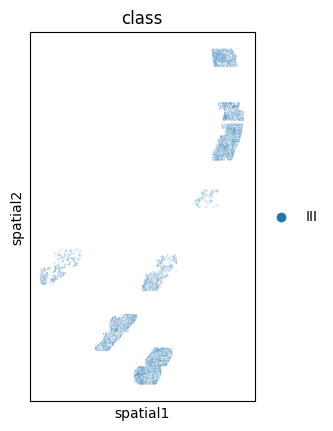

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/Control2_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 77004 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/Control2_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


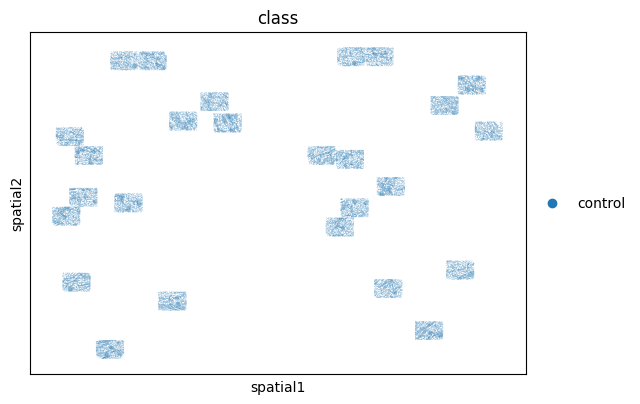

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE6_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 60740 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE6_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


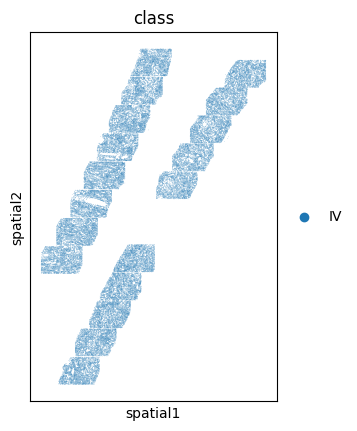

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE3_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 27247 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE3_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


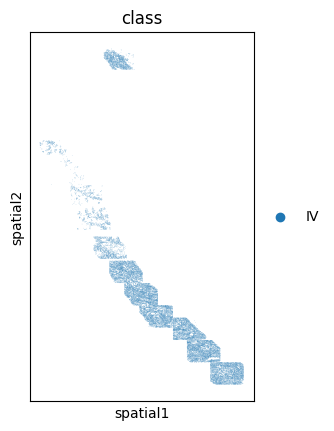

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE4_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 49093 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE4_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


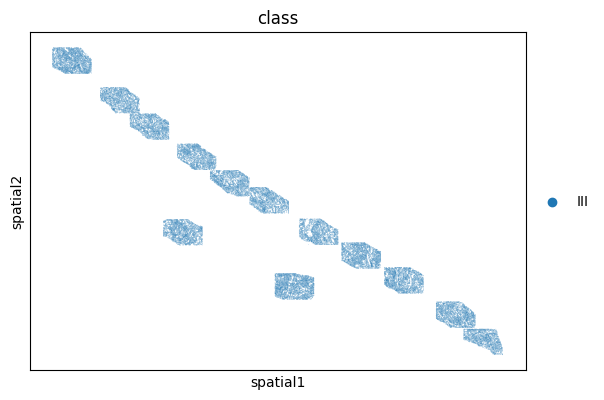

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/Control1_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 26112 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/Control1_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


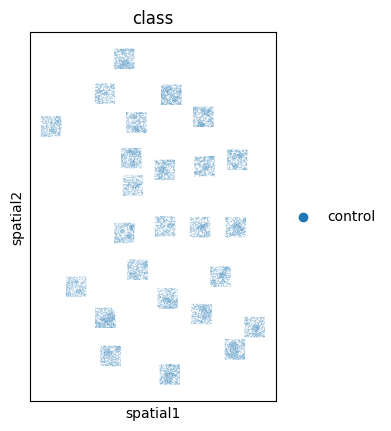

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/Control4_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 10532 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/Control4_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


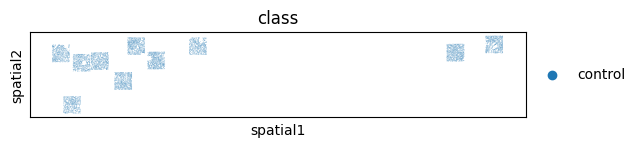

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE1_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 18784 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE1_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


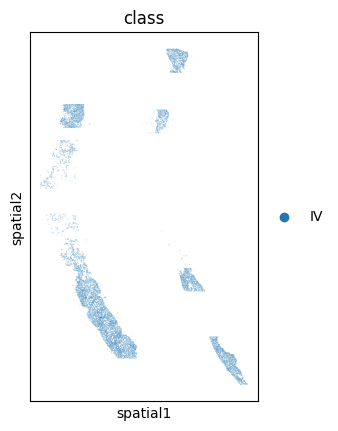

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE7_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 11839 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE7_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


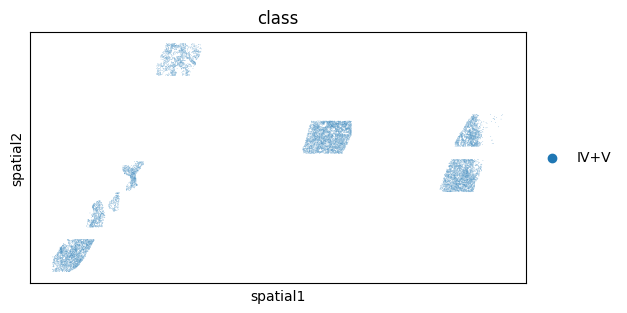

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/Control3_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 130220 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/Control3_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


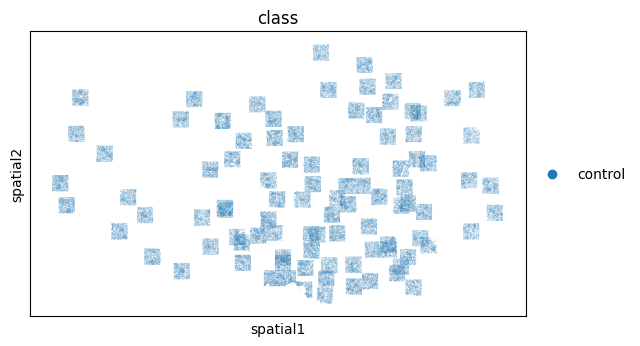

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE8.3_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 33404 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE8.3_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


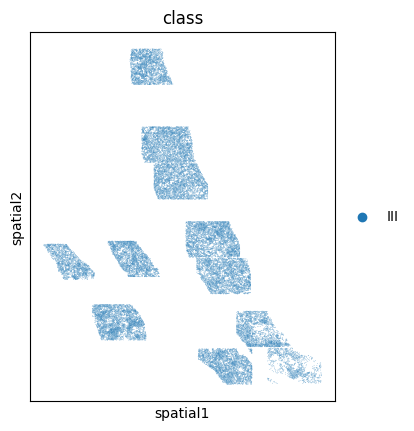

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE2_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 12926 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE2_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


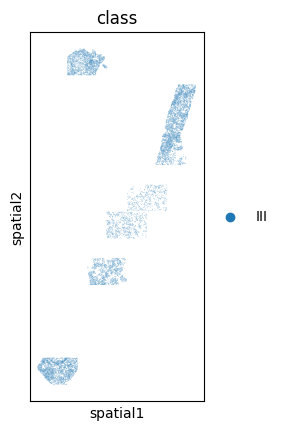

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE8.2_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 30671 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE8.2_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


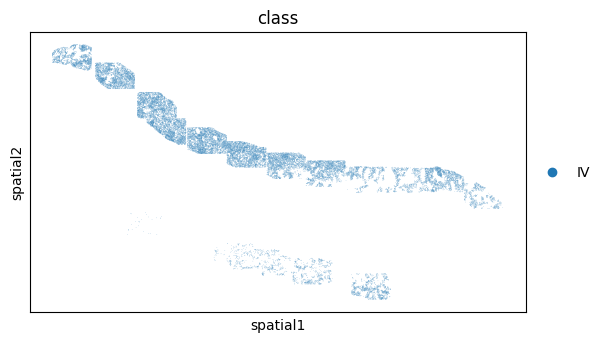

Reading /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE8.1_cosmx_raw.h5ad.gz.
AnnData object with n_obs × n_vars = 16025 × 957
    obs: 'cell_id', 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'tissue', 'Run_Tissue_name', 'Panel', 'negmean', 'slidename', 'tissueslide', 'class', 'tissuename', 'totalcounts', 'x', 'y'
    obsm: 'spatial'
/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/adatafiles_zeroshot/LNCosMx_h5ads/SLE8.1_cosmx_raw.h5ad.gz


/tmp/ipykernel_3346085/287971842.py:19: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


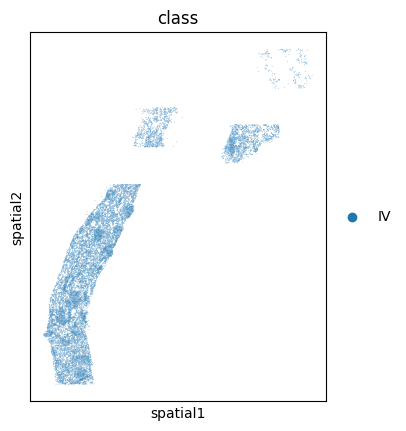

In [51]:
if folder_path:
    for filename in os.listdir(folder_path):
        if filename.endswith(".h5ad") or filename.endswith(".h5ad.gz"):
            file_path = os.path.join(folder_path, filename)
            print(f"Reading {file_path}.")
    
            # Load AnnData
            adata = sc.read_h5ad(file_path)
            adata.obsm['spatial'] = np.column_stack((
                adata.obs['x'].values,
                adata.obs['y'].values))
            del(adata.raw)
            print(adata)
            print(file_path)
            os.makedirs(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/preprocessed_data/{file_path.split("/")[-2]}', exist_ok=True)
            adata.write(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/preprocessed_data/{file_path.split("zeroshot/")[-1]}')
            
            # (Optional): plot each tissue with labels 
            sc.pl.spatial(adata,
                          spot_size=spot_size,
                          color=label_key)